<a href="https://colab.research.google.com/github/andi-wahyudi/student-performance-predictor/blob/main/notebooks/testing_student_pweformance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [ ]:
from google.colab import files

uploaded = files.upload()

if not uploaded:
    raise ValueError("Belum ada file yang diunggah. Silakan upload file ZIP dataset.")

uploaded_names = list(uploaded.keys())
print("File yang diunggah:", uploaded_names)

Saving student+performance.zip to student+performance (2).zip
File yang diunggah: ['student+performance (2).zip']


In [ ]:
DATA_DIR = Path("/content/student_performance")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Simpan file upload ke folder kerja
for filename, content in uploaded.items():
    destination = DATA_DIR / Path(filename).name
    destination.write_bytes(content)

# Ekstrak arsip ZIP secara berulang sampai tidak ada ZIP baru
extracted_archives = set()

while True:
    zip_files = [
        p for p in DATA_DIR.rglob("*.zip")
        if str(p.resolve()) not in extracted_archives
    ]

    if not zip_files:
        break

    for zip_path in zip_files:
        target_dir = zip_path.parent / zip_path.stem
        target_dir.mkdir(parents=True, exist_ok=True)

        try:
            with zipfile.ZipFile(zip_path, "r") as zf:
                zf.extractall(target_dir)
            extracted_archives.add(str(zip_path.resolve()))
            print(f"Berhasil mengekstrak: {zip_path.name}")
        except zipfile.BadZipFile:
            print(f"Peringatan: {zip_path.name} bukan ZIP yang valid.")

print("\nProses ekstraksi selesai.")
print("Lokasi folder data:", DATA_DIR)

Berhasil mengekstrak: student+performance (2).zip
Berhasil mengekstrak: student+performance (1).zip
Berhasil mengekstrak: student.zip
Berhasil mengekstrak: student.zip

Proses ekstraksi selesai.
Lokasi folder data: /content/student_performance


In [ ]:
def find_csv(root_folder, expected_name):
    matches = list(Path(root_folder).rglob(expected_name))
    if not matches:
        raise FileNotFoundError(
            f"File {expected_name} tidak ditemukan. "
            "Periksa kembali ZIP yang diunggah."
        )
    return matches[0]

mat_path = find_csv(DATA_DIR, "student-mat.csv")
por_path = find_csv(DATA_DIR, "student-por.csv")

df_mat = pd.read_csv(mat_path, sep=";")
df_por = pd.read_csv(por_path, sep=";")

print("Lokasi Matematika:", mat_path)
print("Lokasi Bahasa Portugis:", por_path)
print("Ukuran student-mat:", df_mat.shape)
print("Ukuran student-por:", df_por.shape)

Lokasi Matematika: /content/student_performance/student+performance (2)/student/student-mat.csv
Lokasi Bahasa Portugis: /content/student_performance/student+performance (2)/student/student-por.csv
Ukuran student-mat: (395, 33)
Ukuran student-por: (649, 33)


In [ ]:
print("===== DATA MATEMATIKA: 5 BARIS PERTAMA =====")
display(df_mat.head())

print("\n===== DATA BAHASA PORTUGIS: 5 BARIS PERTAMA =====")
display(df_por.head())

print("\nKolom Matematika:")
print(df_mat.columns.tolist())

print("\nKolom Bahasa Portugis:")
print(df_por.columns.tolist())

===== DATA MATEMATIKA: 5 BARIS PERTAMA =====


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10



===== DATA BAHASA PORTUGIS: 5 BARIS PERTAMA =====


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13



Kolom Matematika:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Kolom Bahasa Portugis:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [ ]:
print("===== INFO MATEMATIKA =====")
df_mat.info()

print("\n===== INFO BAHASA PORTUGIS =====")
df_por.info()

print("\n===== STATISTIK MATEMATIKA =====")
display(df_mat.describe(include="all").T)

print("\n===== STATISTIK BAHASA PORTUGIS =====")
display(df_por.describe(include="all").T)

===== INFO MATEMATIKA =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-nu

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN



===== STATISTIK BAHASA PORTUGIS =====


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,649,2,GP,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,649,2,F,383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,649.0,NaN,NaN,NaN,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
address,649,2,U,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,649,2,GT3,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,649,2,T,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,649.0,NaN,NaN,NaN,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,NaN,NaN,NaN,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
Mjob,649,5,other,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,649,5,other,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
def quality_report(df, dataset_name):
    print(f"===== KUALITAS DATA: {dataset_name} =====")
    print("Jumlah baris:", len(df))
    print("Jumlah kolom:", df.shape[1])
    print("Total sel kosong:", int(df.isna().sum().sum()))
    print("Jumlah baris duplikat:", int(df.duplicated().sum()))

    missing = df.isna().sum()
    missing = missing[missing > 0]
    if len(missing):
        print("\nKolom dengan nilai kosong:")
        display(missing.to_frame("jumlah_kosong"))
    else:
        print("Tidak ditemukan nilai kosong.")

quality_report(df_mat, "Matematika")
quality_report(df_por, "Bahasa Portugis")

===== KUALITAS DATA: Matematika =====
Jumlah baris: 395
Jumlah kolom: 33
Total sel kosong: 0
Jumlah baris duplikat: 0
Tidak ditemukan nilai kosong.
===== KUALITAS DATA: Bahasa Portugis =====
Jumlah baris: 649
Jumlah kolom: 33
Total sel kosong: 0
Jumlah baris duplikat: 0
Tidak ditemukan nilai kosong.


In [ ]:
grade_cols = ["G1", "G2", "G3"]

for name, df in [("Matematika", df_mat), ("Bahasa Portugis", df_por)]:
    print(f"===== {name} =====")
    missing_grade_cols = [c for c in grade_cols if c not in df.columns]
    if missing_grade_cols:
        print("Kolom nilai yang tidak ditemukan:", missing_grade_cols)
        continue

    display(df[grade_cols].describe().T)
    print("Tipe data:")
    print(df[grade_cols].dtypes)

===== Matematika =====


,count,mean,std,min,25%,50%,75%,max
G1,395.0,10.908861,3.319195,3.0,8.0,11.0,13.0,19.0
G2,395.0,10.713924,3.761505,0.0,9.0,11.0,13.0,19.0
G3,395.0,10.415190,4.581443,0.0,8.0,11.0,14.0,20.0


Tipe data:
G1    int64
G2    int64
G3    int64
dtype: object
===== Bahasa Portugis =====


,count,mean,std,min,25%,50%,75%,max
G1,649.0,11.399076,2.745265,0.0,10.0,11.0,13.0,19.0
G2,649.0,11.570108,2.913639,0.0,10.0,11.0,13.0,19.0
G3,649.0,11.906009,3.230656,0.0,10.0,12.0,14.0,19.0


Tipe data:
G1    int64
G2    int64
G3    int64
dtype: object


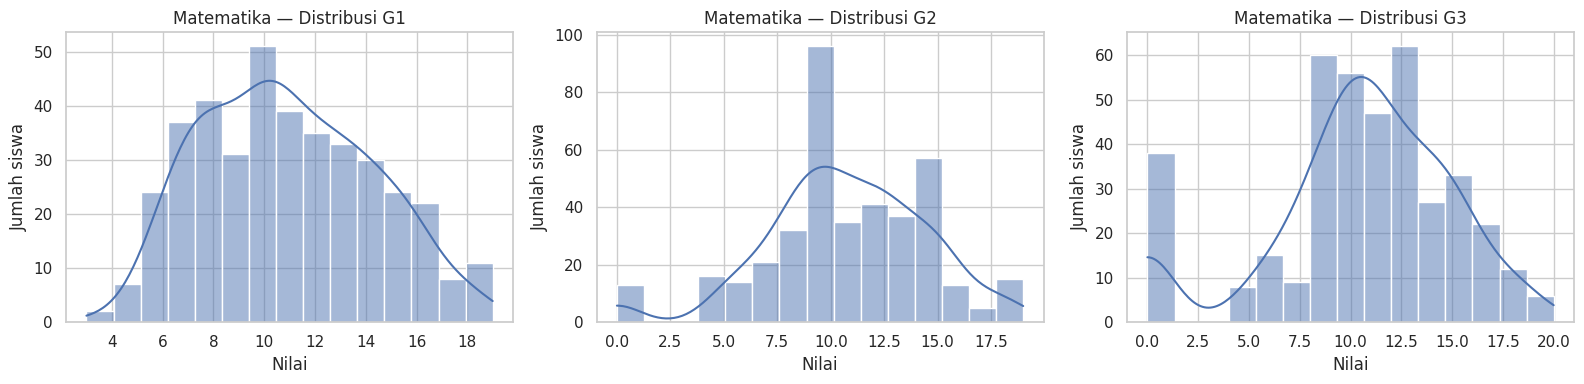

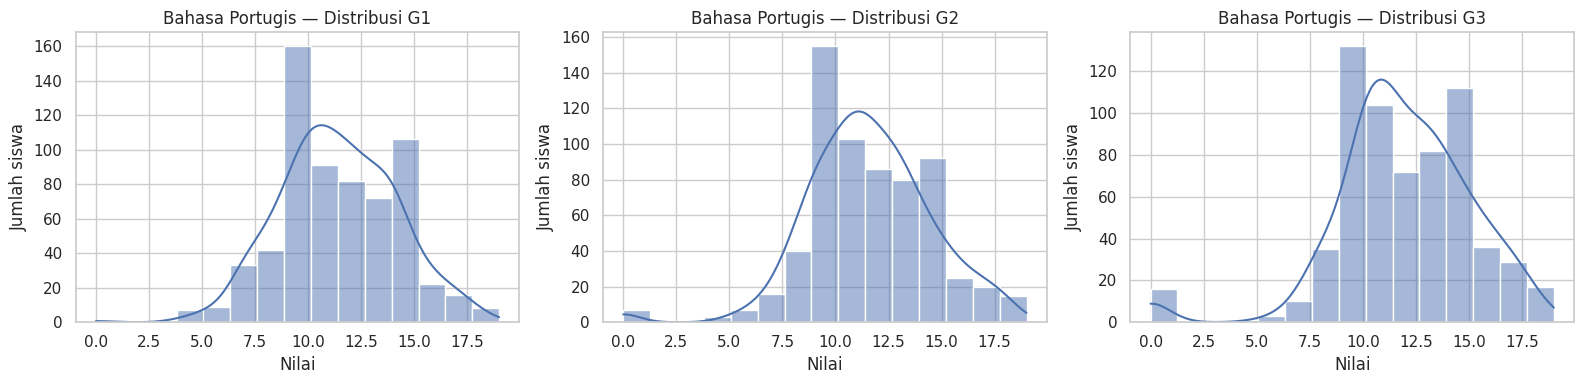

In [ ]:
def plot_grade_distributions(df, dataset_name):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    for ax, col in zip(axes, ["G1", "G2", "G3"]):
        sns.histplot(data=df, x=col, bins=15, kde=True, ax=ax)
        ax.set_title(f"{dataset_name} — Distribusi {col}")
        ax.set_xlabel("Nilai")
        ax.set_ylabel("Jumlah siswa")

    plt.tight_layout()
    plt.show()

plot_grade_distributions(df_mat, "Matematika")
plot_grade_distributions(df_por, "Bahasa Portugis")

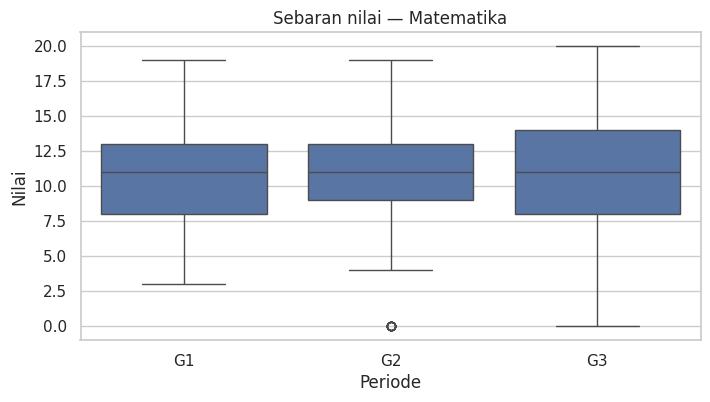

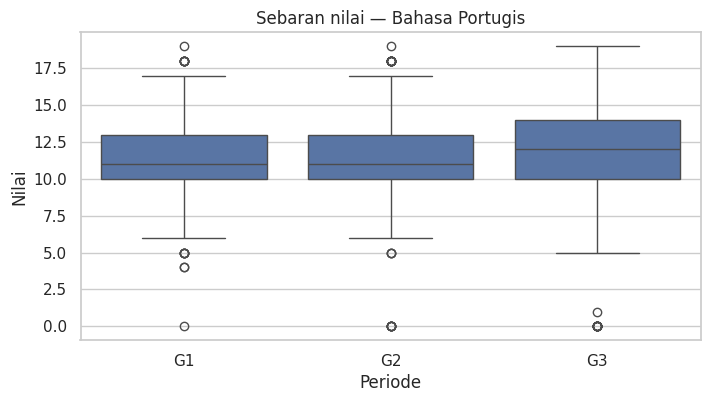

In [ ]:
def plot_grade_boxplots(df, dataset_name):
    plt.figure(figsize=(8, 4))
    long_df = df[["G1", "G2", "G3"]].melt(
        var_name="Periode", value_name="Nilai"
    )
    sns.boxplot(data=long_df, x="Periode", y="Nilai")
    plt.title(f"Sebaran nilai — {dataset_name}")
    plt.show()

plot_grade_boxplots(df_mat, "Matematika")
plot_grade_boxplots(df_por, "Bahasa Portugis")

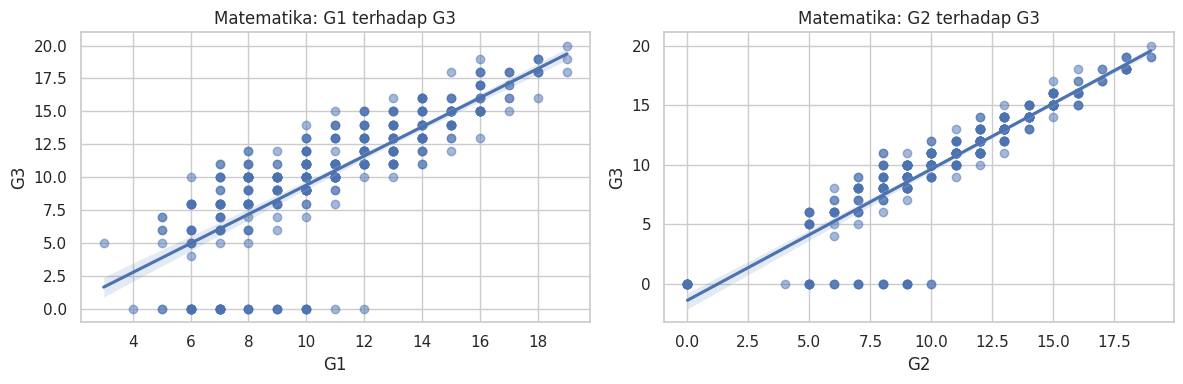

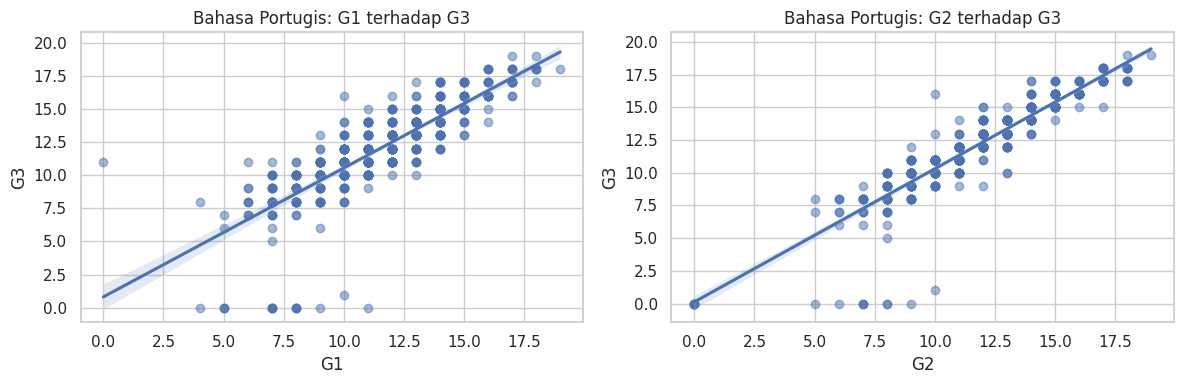

In [ ]:
def plot_grade_relationships(df, dataset_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.regplot(data=df, x="G1", y="G3", ax=axes[0],
                scatter_kws={"alpha": 0.5})
    axes[0].set_title(f"{dataset_name}: G1 terhadap G3")

    sns.regplot(data=df, x="G2", y="G3", ax=axes[1],
                scatter_kws={"alpha": 0.5})
    axes[1].set_title(f"{dataset_name}: G2 terhadap G3")

    plt.tight_layout()
    plt.show()

plot_grade_relationships(df_mat, "Matematika")
plot_grade_relationships(df_por, "Bahasa Portugis")

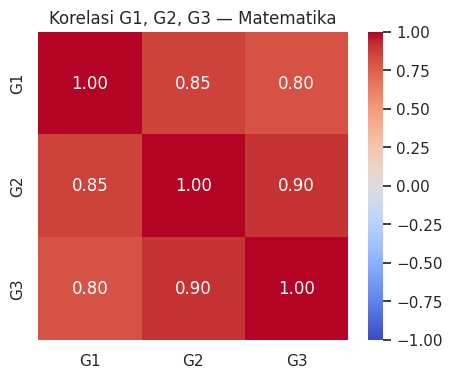

,G1,G2,G3
G1,1.000000,0.852118,0.801468
G2,0.852118,1.000000,0.904868
G3,0.801468,0.904868,1.000000


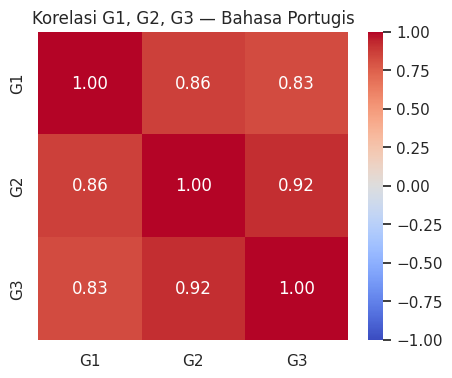

,G1,G2,G3
G1,1.000000,0.864982,0.826387
G2,0.864982,1.000000,0.918548
G3,0.826387,0.918548,1.000000


In [ ]:
def plot_grade_correlation(df, dataset_name):
    corr = df[["G1", "G2", "G3"]].corr(method="pearson")

    plt.figure(figsize=(5, 4))
    sns.heatmap(corr, annot=True, cmap="coolwarm",
                vmin=-1, vmax=1, fmt=".2f")
    plt.title(f"Korelasi G1, G2, G3 — {dataset_name}")
    plt.show()

    display(corr)

plot_grade_correlation(df_mat, "Matematika")
plot_grade_correlation(df_por, "Bahasa Portugis")

,Matematika,Bahasa Portugis
G1,10.91,11.40
G2,10.71,11.57
G3,10.42,11.91


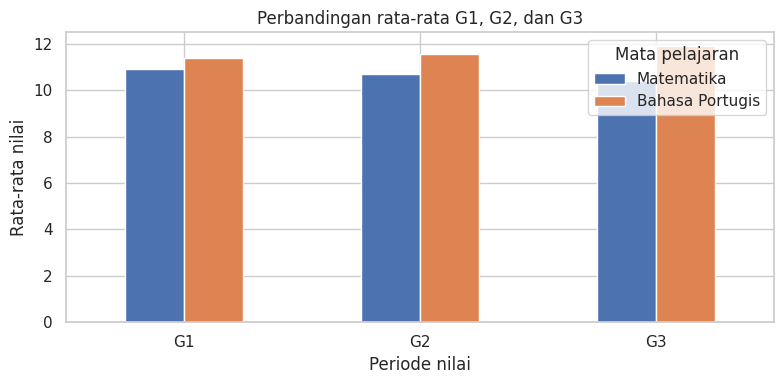

In [ ]:
comparison = pd.DataFrame({
    "Matematika": df_mat[["G1", "G2", "G3"]].mean(),
    "Bahasa Portugis": df_por[["G1", "G2", "G3"]].mean()
})

display(comparison.round(2))

comparison.plot(kind="bar", figsize=(8, 4))
plt.title("Perbandingan rata-rata G1, G2, dan G3")
plt.ylabel("Rata-rata nilai")
plt.xlabel("Periode nilai")
plt.xticks(rotation=0)
plt.legend(title="Mata pelajaran")
plt.tight_layout()
plt.show()

In [ ]:
candidate_cols = [
    "studytime", "failures", "absences",
    "schoolsup", "famsup", "activities",
    "higher", "internet"
]

def summarize_candidate_features(df, dataset_name):
    available = [c for c in candidate_cols if c in df.columns]
    print(f"===== {dataset_name} =====")
    for col in available:
        print(f"\nDistribusi {col}:")
        display(df[col].value_counts(dropna=False).to_frame("jumlah"))

summarize_candidate_features(df_mat, "Matematika")
summarize_candidate_features(df_por, "Bahasa Portugis")

===== Matematika =====

Distribusi studytime:


,jumlah
studytime,
2,198
1,105
3,65
4,27



Distribusi failures:


,jumlah
failures,
0,312
1,50
2,17
3,16



Distribusi absences:


,jumlah
absences,
0,115
2,65
4,53
6,31
8,22
10,17
14,12
12,12
3,8


... (22 outputs left out)


Distribusi higher:


,jumlah
higher,
yes,580
no,69



Distribusi internet:


,jumlah
internet,
yes,498
no,151


In [ ]:
OUTPUT_DIR = Path("/content/eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df_mat.to_csv(OUTPUT_DIR / "student-mat-clean-read.csv", index=False)
df_por.to_csv(OUTPUT_DIR / "student-por-clean-read.csv", index=False)

summary = pd.DataFrame({
    "Matematika": df_mat[["G1", "G2", "G3"]].agg(["count", "mean", "median", "std", "min", "max"]).T["mean"],
    "Bahasa Portugis": df_por[["G1", "G2", "G3"]].agg(["count", "mean", "median", "std", "min", "max"]).T["mean"]
})
summary.to_csv(OUTPUT_DIR / "mean_grade_summary.csv")

print("File output tersimpan di:", OUTPUT_DIR)
print(list(OUTPUT_DIR.iterdir()))

File output tersimpan di: /content/eda_outputs
[PosixPath('/content/eda_outputs/mean_grade_summary.csv'), PosixPath('/content/eda_outputs/student-mat-clean-read.csv'), PosixPath('/content/eda_outputs/student-por-clean-read.csv')]
